# Calibration à budget limité sous décalages spatio-temporels

Cette extension du projet de M1 étudie la classification d'un accident corporel enregistré comme mortel. Elle demande comment répartir un budget limité d'étiquettes dans des départements absents de l'apprentissage après transfert vers 2025. L'objectif est de protéger la classe mortelle et les régions tout en conservant des ensembles de prédiction informatifs.

Le travail est réalisé par [Yaaaxin](https://github.com/Yaaaxin) et [zhailucc](https://github.com/zhailucc). Les méthodes sont connues ; l'apport est leur comparaison sous un protocole spatio-temporel gelé et l'évaluation d'une hypothèse d'allocation.

## Données et cible

Les tables BAAC Caractéristiques, Lieux et Usagers couvrent 2019–2025. L'unité est l'accident. La cible vaut 1 si au moins un usager enregistré porte `grav=2`, décès sur le coup ou dans les trente jours. Une gravité inconnue ne devient jamais une absence de décès ; Usagers sert uniquement à construire la cible.

Les variables du modèle décrivent le temps, les conditions et la route. Identifiants, département, adresse, coordonnées, collision et caractéristiques des victimes sont exclus. Les lignes Lieux multiples sont agrégées à l'accident.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / 'research_v2').exists():
    ROOT = ROOT.parent
RESULTS = ROOT / 'research_v2/results'
final = pd.read_csv(RESULTS / 'final/metrics.csv')
paired = pd.read_csv(RESULTS / 'paired_allocation.csv')
simulation = pd.read_csv(RESULTS / 'simulation_summary_clean.csv')
print(f'{len(final)} évaluations finales agrégées ; {final[["split", "model"]].drop_duplicates().shape[0]} scénarios modèle × découpage.')

180 évaluations finales agrégées ; 6 scénarios modèle × découpage.


## Protocole gelé

Pour une année cible, les années jusqu'à *t−2* ajustent le prédicteur. L'année *t−1* est divisée entre validation, calibration de Platt et calibration conforme source. Dans l'année cible, les identifiants fixent un pool d'adaptation et un test disjoints. Vingt départements sont réservés dans chacun de trois découpages.

Les années 2022–2024 servent à arrêter les choix. La configuration et les empreintes sont gelées avant l'ouverture des étiquettes 2025. On compare régression logistique et gradient boosting, trois graines d'acquisition et des budgets de 500, 1 000 et 2 000 labels.

## Références sans étiquette cible

La référence pooled calibre un seuil unique sur la source. La référence par classe sépare décès et non-décès. Le bras sans étiquette estime un rapport de densités avec les caractéristiques du pool cible, puis utilise un quantile pondéré.

In [2]:
baseline = (final[final.budget == 0]
            .groupby('method')[['coverage', 'fatal_coverage', 'mean_size', 'singleton_rate', 'average_precision', 'brier']]
            .mean().reindex(['source_pooled', 'source_weighted', 'source_class']))
baseline.round(3)

Out[1]: 
                 coverage  fatal_coverage  ...  average_precision  brier
method                                     ...                          
source_pooled       0.907            0.00  ...              0.153  0.049
source_weighted     0.887            0.00  ...              0.153  0.049
source_class        0.911            0.91  ...              0.153  0.049

[3 rows x 6 columns]


La couverture globale de la calibration pooled est proche de 0,9, mais sa couverture mortelle est nulle dans les six scénarios. La pondération par caractéristiques cibles ne corrige pas cette défaillance. La calibration par classe atteint environ 0,91 pour la classe mortelle avec une taille moyenne de 1,53.

## Budgets locaux

Les seuils sont calculés par département × classe. Une cellule fatale contient un seuil fini seulement avec au moins neuf décès à α=0,10. La règle candidate dépense d'abord jusqu'à cinq labels par département, les exclut des quantiles, estime la rareté, puis alloue le reste en minimisant un critère substitutif de variance. Le pilot est inclus dans le coût total.

In [3]:
local = (final[final.budget > 0]
         .groupby(['method', 'budget'])[['coverage', 'fatal_coverage', 'mean_size', 'singleton_rate', 'fatal_cells_infinite']]
         .mean())
local.round(3)

Out[1]: 
                       coverage  ...  fatal_cells_infinite
method         budget            ...                      
pilot_variance 500        0.919  ...                19.333
               1000       0.908  ...                18.222
               2000       0.902  ...                12.000
proportional   500        0.921  ...                19.333
               1000       0.906  ...                18.778
               2000       0.904  ...                14.444
uniform        500        0.926  ...                19.333
               1000       0.908  ...                17.778
               2000       0.903  ...                11.778

[9 rows x 5 columns]


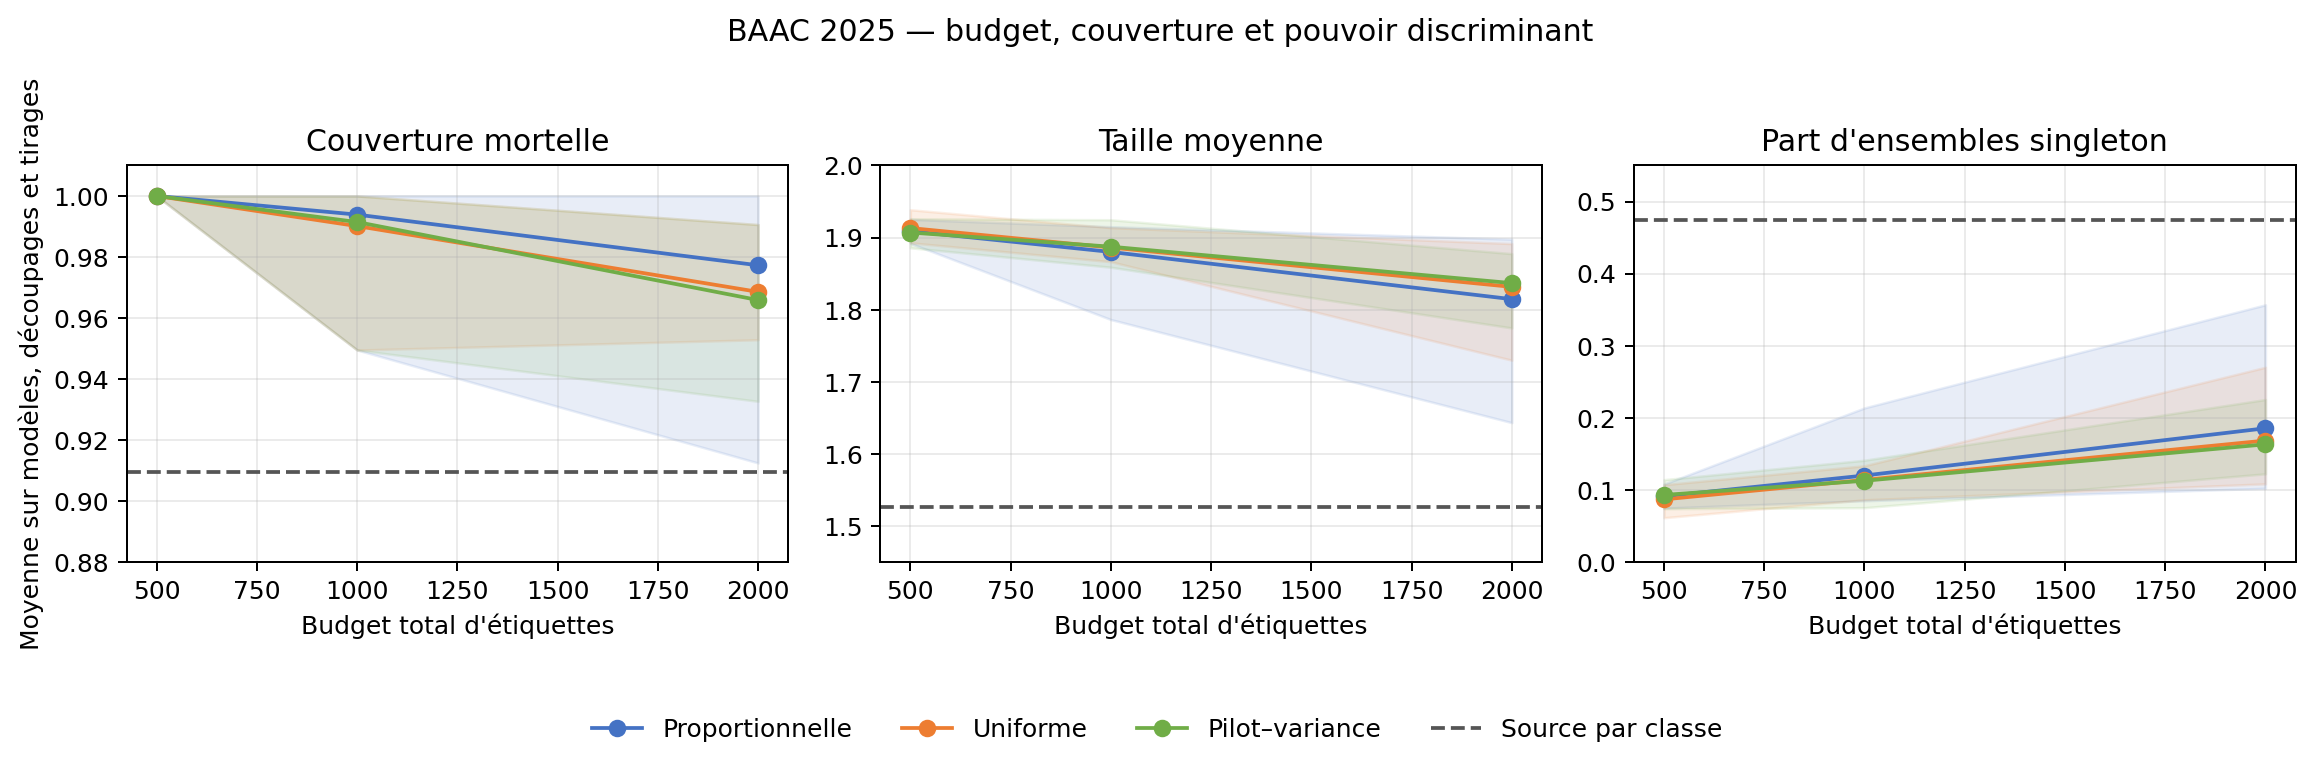

In [4]:
display(Image(filename=str(RESULTS / 'figures/budget_tradeoff.png'), width=1000))

À budget 500, la couverture mortelle égale 1 surtout parce que presque tous les seuils fatals sont infinis : les ensembles contiennent presque toujours les deux classes. À 2 000, les ensembles se contractent, mais restent plus grands que ceux de la calibration source par classe.

## La règle candidate améliore-t-elle l'allocation ?

In [5]:
comparison = paired[(paired.phase == 'final') & (paired.reference == 'uniform')]
comparison.pivot(index='budget', columns='metric', values='difference_moyenne')[['coverage', 'fatal_coverage', 'mean_size', 'singleton_rate']].round(4)

Out[1]: 
metric  coverage  fatal_coverage  mean_size  singleton_rate
budget                                                     
500      -0.0065          0.0000    -0.0062          0.0062
1000      0.0001          0.0013     0.0012         -0.0012
2000     -0.0004         -0.0027     0.0052         -0.0052


Les différences sont petites, changent de signe entre budgets, modèles, régions et tirages, et ne reproduisent pas un bénéfice stable entre 2019–2024 et 2025. Le mécanisme candidat est donc rejeté comme amélioration empirique dans ce régime. L'allocation proportionnelle donne même une couverture mortelle moyenne légèrement supérieure en 2025.

## Simulation et conditions d'échec

La simulation utilise huit régions, une classe rare et quatre mécanismes : échangeabilité, décalage source–cible, rupture entre calibration et test, et effet régional commun. Elle ne cherche pas à imiter BAAC.

In [6]:
simulation[(simulation.method.isin(['source_pooled', 'source_class', 'uniform', 'pilot_variance'])) &
           (simulation.budget.isin([0, 600]))][['condition', 'method', 'budget', 'coverage_mean', 'fatal_coverage_mean', 'mean_size_mean']].round(3)

Out[1]: 
                   condition  ... mean_size_mean
1      correlation_regionale  ...          1.651
4      correlation_regionale  ...          1.321
5      correlation_regionale  ...          1.300
7      correlation_regionale  ...          1.643
9      decalage_source_cible  ...          1.607
12     decalage_source_cible  ...          1.321
13     decalage_source_cible  ...          1.301
15     decalage_source_cible  ...          1.598
17               echangeable  ...          1.747
20               echangeable  ...          1.489
21               echangeable  ...          1.032
23               echangeable  ...          1.738
25  rupture_calibration_test  ...          1.607
28  rupture_calibration_test  ...          1.321
29  rupture_calibration_test  ...          1.301
31  rupture_calibration_test  ...          1.598

[16 rows x 6 columns]


Sous échangeabilité, la calibration atteint la cible ou devient conservatrice. Sous rupture calibration–test, la couverture locale peut s'effondrer quand les seuils deviennent plus informatifs. La grande taille à faible budget peut masquer cette rupture.

## Conclusion et limites

La protection de la classe mortelle exige une calibration par classe. Dans ces données, la subdivision supplémentaire par département consomme trop d'observations : 500 et 1 000 labels donnent surtout des ensembles conservateurs, et 2 000 labels ne suffisent pas à rendre la règle pilot–variance meilleure que les allocations simples. La calibration source par classe constitue le compromis le plus compact observé.

Quarante-deux des 58 couples découpage–département ont moins de vingt décès test. Les découpages se recouvrent, la dépendance spatiale persiste et la stabilité entre adaptation et test n'est pas démontrée. L'analyse ne couvre pas les décès non enregistrés et ne doit pas être interprétée causalement.